# <a id='toc1_'></a>[KNN](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [KNN](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
    - [Separação treino e teste - validação cruzada](#toc1_2_1_)    
    - [Aplicando o KNN](#toc1_2_2_)    
    - [Otimização de hiperparâmetros](#toc1_2_3_)    
    - [Analisando os resultados](#toc1_2_4_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Nesse notebook, iremos implementar o modelo KNN ao nosso dataset. Depois de implementá-lo, também vamos otimizar seus hiperparâmetros e comparar os resultados obtidos com outros modelos.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Vamos iniciar coletando e tratando os dados que iremos utilizar, como feito no notebook [01.A - Baseline](01.A%20-%20Baseline.ipynb). Dessa vez, como vamos realizar a otimização, vamos dividir nosso conjunto em dados de treino e dados de teste.

In [190]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

ATTRIBUTES = [
    "epicenter_distance",
    "geodesic_distance",
    "azimuth_degree",
    "magnitude",
    "magnitude_type",
    "depth",
    "first_arrival_time_delta",
    "arrival_time_delta",
    "land_fraction",
    "origin_plate"
]

TARGET = [
    "amplitude_factor_log10"
]

df_earthquakes = pd.read_csv("../00 - Coleta e Tratamento de Dados/Data/earthquake_dataset_treated.csv")

CATEGORICAL_ATTRIBUTES = ["magnitude_type", "origin_plate"]
NUMERICAL_ATTRIBUTES = [
    column for column in X.columns
    if column not in CATEGORICAL_ATTRIBUTES
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_ATTRIBUTES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_ATTRIBUTES
        )
    ]
)

### <a id='toc1_2_1_'></a>[Separação treino e teste - validação cruzada](#toc0_)

Para dividir os dados de treino e teste, de forma à estimar as métricas dos modelos induzidos de uma forma mais confiável, iremos utilizar a técnica de **Validação cruzada**. Mais especificamente, aplicaremos o método $k$-fold, a partir da biblioteca `scikit-learn`.

In [191]:
from sklearn.model_selection import KFold

NUM_FOLDS = 10
RANDOM_STATE = 424242

TEST_SIZE = 0.1

X = df_earthquakes.reindex(ATTRIBUTES, axis=1)
y = df_earthquakes.reindex(TARGET, axis=1)

df_earthquakes = df_earthquakes.reindex(ATTRIBUTES + TARGET, axis=1)

y_bins = pd.qcut(
    y.values.ravel(),
    q=5,
    labels=False,
    duplicates="drop"
)

idx = df_earthquakes.index
train_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_bins)

df_train = df_earthquakes.iloc[train_idx]
df_test = df_earthquakes.iloc[test_idx]

X_train = df_train.reindex(ATTRIBUTES, axis=1)
y_train = df_train.reindex(TARGET, axis=1)

X_test = df_test.reindex(ATTRIBUTES, axis=1)
y_test = df_test.reindex(TARGET, axis=1)

kf = KFold(NUM_FOLDS, shuffle=True, random_state=RANDOM_STATE)

### <a id='toc1_2_2_'></a>[Aplicando o KNN](#toc0_)

Vamos utilizar o `KNeighborsRegressor` do **scikit-learn** para induzir nosso modelo, de acordo com a referência [2].

Para o algoritmo de KNN, o ideal é normalizarmos os nossos dados, pois ele é sensível à escala dos atributos. Vamos utilizar o `StandardScaler` para aplicar a normalização padrão ao nosso dataset.

A métrica que utilizaremos de referência será o RMSE, que é a raiz do erro quadrático médio das previsões do nosso modelo.

As métricas foram:
 0 - 0.574759125051276
 1 - 0.35303972553941876
 2 - 0.43834963766518886
 3 - 0.6460921886114551
 4 - 0.35069859771074896
 5 - 0.24889473266509524
 6 - 0.2888481435479031
 7 - 0.49630101282535627
 8 - 0.5212478972668647
 9 - 0.6325442078262216


A média das métricas é de: 0.4550775268709528


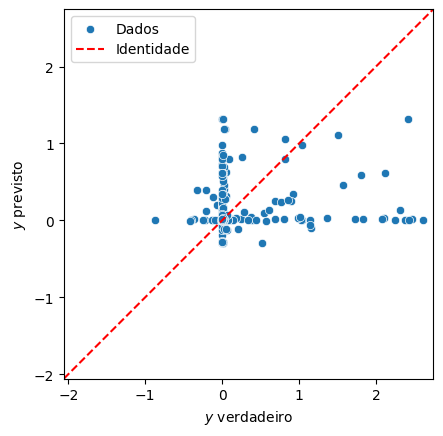

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error
import seaborn as sns
import numpy as np

NUM_VIZINHOS = 3

knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("regressor", KNeighborsRegressor(NUM_VIZINHOS))
    ]
)

def test_kf(model, X=X, y=y, kf=kf, plot=True):
    metrics = []
    true_y = []
    pred_y = []

    for train_idx, test_idx in kf.split(X):

        X_train_, X_test_ = X.iloc[train_idx], X.iloc[test_idx]
        y_train_, y_test_ = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train_, y_train_)

        true_y_ = y_test_
        pred_y_ = model.predict(X_test_)
        
        true_y.append(true_y_)
        pred_y.append(pred_y_)

        RMSE = root_mean_squared_error(true_y_, pred_y_)

        metrics.append(RMSE)

    if plot:
        print("As métricas foram:\n", *[f"{i} - {metric}\n" for i, metric in enumerate(metrics)])
        print()
        print("A média das métricas é de:", np.mean(metrics))

        true_y = np.concatenate(true_y).ravel()
        pred_y = np.concatenate(pred_y).ravel()

        min_val = min(true_y.min(), pred_y.min())
        max_val = max(true_y.max(), pred_y.max())

        interval = [min_val * 0.95, max_val * 1.05]

        ax = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
        ax.plot(interval, interval, "r--", label="Identidade")

        ax.set(
            xlabel="$y$ verdadeiro",
            ylabel="$y$ previsto",
            xlim=interval,
            ylim=interval,
            aspect="equal",
        )
        ax.legend();
    
    return metrics
    
knn_metrics = test_kf(knn_model)

Podemos ver que já houve uma tentativa diferente do modelo para tentar prever cada uma das ampitudes. Entretanto, o modelo utilizado parece não ter atingido uma complexidade suficiente para aprimorar o resultado obtido pelo baseline. Vamos ver como ele se comporta ao otmizar os os hiperparâmetros utilizando o optuna.

### <a id='toc1_2_3_'></a>[Otimização de hiperparâmetros](#toc0_)

Primeiro, vamos montar a função que instancia o modelo, de acordo com os valores sorteados pelo optuna. Para os atributos iremos definir as seguintes opções:
- `n_neighbors`: varia de 1 à 41, com passo 2. Assim, consideramos um grande espaço que engloba desde vizinhanças locais até as mais distantes, pensando no tamanho do nosso conjunto
- `weights`: podemos escolher entre  "uniform" ou "distance", para comparar as duas opções
- `p`: vamos escolher a potência minkowski entre 1 e 2 para encontrar a melhor métrica: manhattan ou euclideana.
- `normalize`: define se os dados serão normalizados pelo normalizador padrão ou não.

In [193]:
def create_model_instance(trial):
    params = {
        "n_neighbors": trial.suggest_int("n_neighbors", 1, 41, step=2),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "p": trial.suggest_categorical("minkowski_potential", [1, 2]),
    }
    
    normalize = trial.suggest_categorical("normalize", [True, False])
    
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", KNeighborsRegressor(**params))
    ]
    
    if normalize: steps.insert(1, ("scaler", StandardScaler()))
    
    
    knn_model = Pipeline(steps)
    
    return knn_model

Agora, vamos definir a função objetivo, que vai medir a métrica do modelo.

In [194]:
def objective_function(trial, X, y, kf, num_folds):
    model = create_model_instance(trial)
    
    metrics = test_kf(model, X, y, kf, plot=False)
    
    return np.mean(metrics)

Então, vamos criar o objeto de estudo, que será responsável por buscar os melhores hiperparâmetros do espaço delimitado

In [195]:
from optuna import create_study, delete_study

STUDY_NAME = "Studies/knn_tiamat"
STORAGE = f"sqlite:///{STUDY_NAME}.db"

delete_study(
    study_name=STUDY_NAME,
    storage=STORAGE
)

study_obj = create_study(
    direction="minimize",
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
)

[I 2026-11-16 08:25:59,039] A new study created in RDB with name: Studies/knn_tiamat


Utilizando o funtools. podemos criar nossa função objetiva parcial

In [196]:
from functools import partial

partial_objective_function = partial(
    objective_function, X=X_train, y=y_train, kf=kf, num_folds=NUM_FOLDS
)

In [197]:
print(type(X_train))

<class 'pandas.core.frame.DataFrame'>


E, por fim, otimizamos o estudo a partir do método `optimize`. Vamos utilizar um número de tentativas inicial como 100.

In [198]:
N_TRIALS = 100

study_obj.optimize(partial_objective_function, n_trials=N_TRIALS)

[I 2026-11-16 08:26:01,597] Trial 0 finished with value: 0.45713598639942477 and parameters: {'n_neighbors': 3, 'weights': 'distance', 'minkowski_potential': 2, 'normalize': True}. Best is trial 0 with value: 0.45713598639942477.
[I 2026-11-16 08:26:02,009] Trial 1 finished with value: 0.4652226044153432 and parameters: {'n_neighbors': 13, 'weights': 'distance', 'minkowski_potential': 2, 'normalize': False}. Best is trial 0 with value: 0.45713598639942477.
[I 2026-11-16 08:26:02,304] Trial 2 finished with value: 0.41440918014504946 and parameters: {'n_neighbors': 27, 'weights': 'uniform', 'minkowski_potential': 2, 'normalize': True}. Best is trial 2 with value: 0.41440918014504946.
[I 2026-11-16 08:26:02,552] Trial 3 finished with value: 0.4334339827891801 and parameters: {'n_neighbors': 25, 'weights': 'uniform', 'minkowski_potential': 1, 'normalize': False}. Best is trial 2 with value: 0.41440918014504946.
[I 2026-11-16 08:26:02,813] Trial 4 finished with value: 0.4962782029357209 and

### <a id='toc1_2_4_'></a>[Analisando os resultados](#toc0_)

Vamos observar os resultados do estudo

In [199]:
df = study_obj.trials_dataframe()

df

,number,value,datetime_start,datetime_complete,duration,params_minkowski_potential,params_n_neighbors,params_normalize,params_weights,system_attrs_tpe:relative_params:0,state
0,0,0.457136,2026-11-16 08:26:01.187221,2026-11-16 08:26:01.573273,0 days 00:00:00.386052,2,3,True,distance,NaN,COMPLETE
1,1,0.465223,2026-11-16 08:26:01.605984,2026-11-16 08:26:01.991389,0 days 00:00:00.385405,2,13,False,distance,NaN,COMPLETE
2,2,0.414409,2026-11-16 08:26:02.018980,2026-11-16 08:26:02.285625,0 days 00:00:00.266645,2,27,True,uniform,NaN,COMPLETE
3,3,0.433434,2026-11-16 08:26:02.313570,2026-11-16 08:26:02.533622,0 days 00:00:00.220052,1,25,False,uniform,NaN,COMPLETE
4,4,0.496278,2026-11-16 08:26:02.559475,2026-11-16 08:26:02.775586,0 days 00:00:00.216111,1,3,False,uniform,NaN,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.412169,2026-11-16 08:26:31.301003,2026-11-16 08:26:31.591892,0 days 00:00:00.290889,2,37,True,uniform,"{""minkowski_potential"": 2, ""n_neighbors"": 37, ...",COMPLETE
96,96,0.411529,2026-11-16 08:26:31.620285,2026-11-16 08:26:31.905692,0 days 00:00:00.285407,2,41,True,uniform,"{""minkowski_potential"": 2, ""n_neighbors"": 41, ...",COMPLETE
97,97,0.411434,2026-11-16 08:26:31.949992,2026-11-16 08:26:32.239395,0 days 00:00:00.289403,2,39,True,uniform,"{""minkowski_potential"": 2, ""n_neighbors"": 39, ...",COMPLETE
98,98,0.437071,2026-11-16 08:26:32.260957,2026-11-16 08:26:32.537942,0 days 00:00:00.276985,2,23,False,uniform,"{""minkowski_potential"": 2, ""n_neighbors"": 23, ...",COMPLETE


O melhor resultado pode ser obtido através do atributo `best_trial`

In [200]:
best_trial = study_obj.best_trial

print(f"Número do melhor trial: {best_trial.number}")
print(f"Parâmetros do melhor trial: {best_trial.params}")

Número do melhor trial: 18
Parâmetros do melhor trial: {'n_neighbors': 39, 'weights': 'uniform', 'minkowski_potential': 2, 'normalize': True}


Vamos criar um modelo com o melhor conjunto de hiperparâmetros encontrados e checar seu desempenho.

O RMSE calculado é de: 0.38825956423828134


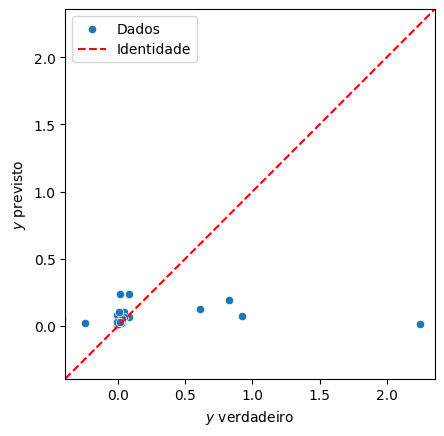

In [ ]:
model = create_model_instance(best_trial)
model.fit(X_train, y_train)

true_y = np.asarray(y_test).ravel()
pred_y = np.asarray(model.predict(X_test)).ravel()

RMSE = root_mean_squared_error(true_y, pred_y)

min_val = min(true_y.min(), pred_y.min())
max_val = max(true_y.max(), pred_y.max())

interval = [min_val * 0.95, max_val * 1.05]

ax = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
ax.plot(interval, interval, "r--", label="Identidade")

ax.set(
    xlabel="$y$ verdadeiro",
    ylabel="$y$ previsto",
    xlim=interval,
    ylim=interval,
    aspect="equal",
)
ax.legend();

print(f"O RMSE calculado é de: {RMSE}")

Aparentemente, o modelo de KNN otimizado conseguiu um RMSE com cerca de 0.37 pontos a menos se comparado ao modelo baseline. Mas isso ainda não quer dizer que o modelo consegue interpretar todo o conjunto de dados, como podemos observar pela dispersão no gráfico de desempenho.

Vamos ver como ficou a importância dos parâmetros de busca de acordo com o optuna

In [203]:
import optuna.visualization as vis 

vis.plot_param_importances(study_obj)

Pelo gráfico, vemos como o número de vizinhos é o hiperparâmetro mais importantes, seguido da normalização, potencial de minkowski e os tipos de pesos, com contribuições despreszíveis.

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Sendo assim, nosso modelo de KNN teve um RMSE levemente abaixo da estimativa do modelo baseline. Entretanto, nem todo o espaço de dados foi coberto, e esse algoritmo pode não ser a melhor opção para o problema em questão.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. **CASSAR, Daniel R.** *ATP-203 1.1 - Tratamento de dados com pandas*. Campinas: Ilum Escola de Ciência, 2026.
2. **CASSAR, Daniel R.** *ATP-203 2.1 - Aprendizado de máquina, k-NN e métricas*. Campinas: Ilum Escola de Ciência, 2026.
3. **CASSAR, Daniel R.** *ATP-203 7.1 - Otimização de hiperparâmetros com optuna*. Campinas: Ilum Escola de Ciência, 2026.